In [69]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

In [70]:
conn = sqlite3.connect("../data/checking-logs.sqlite")

In [71]:
df = pd.io.sql.read_sql(
    """
    ---sql
       SELECT uid, timestamp, numTrials
        FROM checker
        WHERE uid NOT LIKE 'admin_%' and status = 'ready' and labname = 'project1'  ORDER BY uid
     """,
    conn,
    parse_dates="timestamp",
)
df.head(5)

,uid,timestamp,numTrials
0,user_1,2020-05-14 20:56:08.898880,1
1,user_1,2020-05-14 20:58:02.313690,2
2,user_1,2020-05-14 20:58:46.322457,3
3,user_1,2020-05-14 21:08:15.434237,4
4,user_1,2020-05-14 21:10:14.867603,5


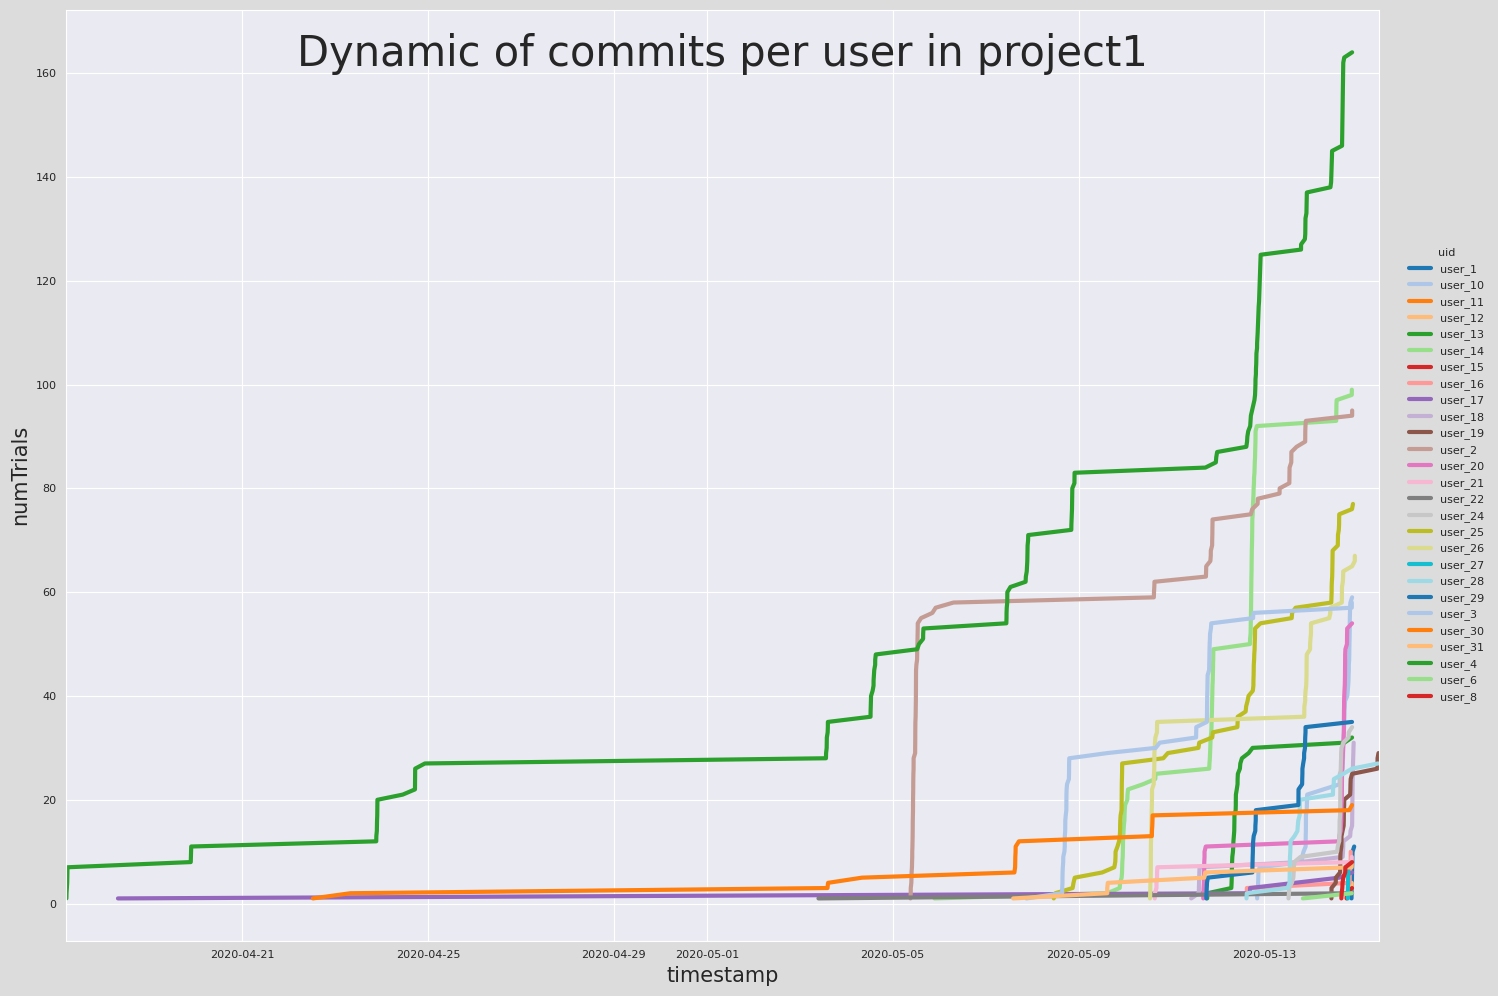

In [72]:
sns.set_style("darkgrid")
plt.rcParams.update({"font.size": 8, "axes.labelsize": 15})
fig, ax = plt.subplots(figsize=(15, 10))
fig.set_facecolor("gainsboro")
palette = sns.color_palette("tab20", n_colors=df["uid"].nunique())
sns.lineplot(
    data=df,
    x="timestamp",
    y="numTrials",
    hue="uid",
    ax=ax,
    linewidth=3,
    palette=palette,
)

ax.set_title("Dynamic of commits per user in project1", fontsize=30, pad=0, y=0.94)
ax.set_xmargin(0)
plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc="center left",
    borderaxespad=0,
    frameon=False,
    title="uid",
)
plt.tight_layout()
plt.show()

In [73]:
conn.close()

### «Какой пользователь почти всё время был лидером по числу коммитов?» Ответ: user_4.
### «Какой пользователь был лидером лишь недолгое время?» Ответ: user_2.